# PulsePoint Clinic: Phase 2 Descriptive Analytics

**Group E² JR** | Input: `cleaned_dataset.csv` (output of the Phase 1 cleaning notebook)

This notebook covers the descriptive half of Phase 2:

1. Feature engineering
2. Exploratory Data Analysis (EDA)
3. Correlation matrix
4. K-Means clustering (tests H3)
5. Association rules (mlxtend)
6. Experiment log and exports

**Outputs written by this notebook**

| File | Contents |
|---|---|
| `results/cluster_assignments.csv` | every appointment with its engineered features and patient cluster |
| `results/cluster_profiles.csv` | size, averages and no-show rate per cluster |
| `results/association_rules.csv` | rules that lead to a no-show, with support, confidence, lift |
| `results/correlation_matrix.csv` | the correlation table behind the heatmap |
| `results/sms_by_lead_time.csv` | the H1 table (no-show rate by SMS within lead-time bucket) |
| `results/experiment_log.csv` | every K-Means and Apriori setting tried, with metrics |
| `figures/*.png` | all charts |

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from mlxtend.frequent_patterns import apriori, association_rules

INPUT_FILE = "cleaned_dataset.csv"   # change if your file lives elsewhere
RANDOM_STATE = 42

os.makedirs("results", exist_ok=True)
os.makedirs("figures", exist_ok=True)
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110

experiment_log = []   # every model run gets appended here

def save(name):
    plt.tight_layout()
    plt.savefig(f"figures/{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


## 1. Load and engineer features

`patient_id` is loaded as text: five IDs contain decimals after cleaning, and reading the column as a number could alter them.

New columns:

- `no_show_flag`: 1 = missed the appointment, 0 = attended
- `lead_days`: days between booking and appointment
- `visit_count`: how many appointments the patient has in the dataset
- `prior_visits`, `prior_no_shows`: the patient's history **before** this booking (known at booking time)
- `appointment_weekday`, `age_group`, `lead_bucket`: groupings used in charts and rules

The 618 rows that are identical except for `appointment_id` are kept, as in Phase 1 (they may be genuine multiple bookings).

In [ ]:
df = pd.read_csv(INPUT_FILE, dtype={"patient_id": str},
                 parse_dates=["scheduled_at", "appointment_date"])

df["no_show_flag"] = (df["no_show"] == "Yes").astype(int)
df["lead_days"] = (df["appointment_date"] - df["scheduled_at"].dt.normalize()).dt.days
df["appointment_weekday"] = df["appointment_date"].dt.day_name()

# Patient history, in booking order
df = df.sort_values(["patient_id", "scheduled_at", "appointment_id"]).reset_index(drop=True)
g = df.groupby("patient_id")
df["visit_count"] = g["appointment_id"].transform("size")
df["prior_visits"] = g.cumcount()
df["prior_no_shows"] = g["no_show_flag"].cumsum() - df["no_show_flag"]

df["age_group"] = pd.cut(df["age"], [-1, 12, 17, 39, 59, 200],
                         labels=["0-12", "13-17", "18-39", "40-59", "60+"])
df["lead_bucket"] = pd.cut(df["lead_days"], [-1, 0, 3, 7, 14, 30, 10_000],
                           labels=["Same day", "1-3 days", "4-7 days", "8-14 days", "15-30 days", "31+ days"])

print("Rows:", len(df), "| Unique patients:", df["patient_id"].nunique())
print("Lead days: min", df["lead_days"].min(), "| max", df["lead_days"].max())
df.head()

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Rows: 110516 | Unique patients: 62296
Lead days: min 0 | max 179


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,patient_id,appointment_id,gender,scheduled_at,appointment_date,age,neighbourhood,scholarship,hypertension,diabetes,...,sms_received,no_show,no_show_flag,lead_days,appointment_weekday,visit_count,prior_visits,prior_no_shows,age_group,lead_bucket
0,11111462625267,5715720,F,2016-05-18 14:58:29,2016-06-08,65,REPÚBLICA,0,1,0,...,1,No,0,21,Wednesday,1,0,0,60+,15-30 days
1,111124532532143,5531224,M,2016-03-31 09:17:26,2016-05-03,9,MARIA ORTIZ,0,0,0,...,1,No,0,33,Tuesday,2,0,0,0-12,31+ days
2,111124532532143,5624030,M,2016-04-26 15:05:58,2016-06-01,9,MARIA ORTIZ,0,0,0,...,1,Yes,1,36,Wednesday,2,1,0,0-12,31+ days
3,11114485119737,5621757,F,2016-04-26 10:46:38,2016-05-25,12,MARIA ORTIZ,0,0,0,...,1,Yes,1,29,Wednesday,1,0,0,0-12,15-30 days
4,11116239871275,5625265,F,2016-04-27 07:05:38,2016-04-29,13,SÃO PEDRO,0,0,0,...,0,No,0,2,Friday,1,0,0,13-17,1-3 days


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


## 2. Exploratory Data Analysis

In [ ]:
overall = df["no_show_flag"].mean()
print(f"Overall no-show rate: {overall:.1%}")
print(df["no_show"].value_counts().to_string())
df[["age", "lead_days", "visit_count", "prior_visits", "prior_no_shows"]].describe().round(2)

Overall no-show rate: 20.2%
no_show
No     88205
Yes    22311


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

,age,lead_days,visit_count,prior_visits,prior_no_shows
count,110516.00,110516.00,110516.00,110516.00,110516.00
mean,37.09,10.18,3.54,1.27,0.23
std,23.10,15.26,6.56,3.91,0.68
min,0.00,0.00,1.00,0.00,0.00
25%,18.00,0.00,1.00,0.00,0.00
50%,37.00,4.00,2.00,0.00,0.00
75%,55.00,15.00,4.00,1.00,0.00
max,102.00,179.00,88.00,87.00,17.00


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


**The classes are imbalanced**: about one appointment in five is a no-show. This matters for the association rules (low support for no-show rules is expected) and for the predictive models later.

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

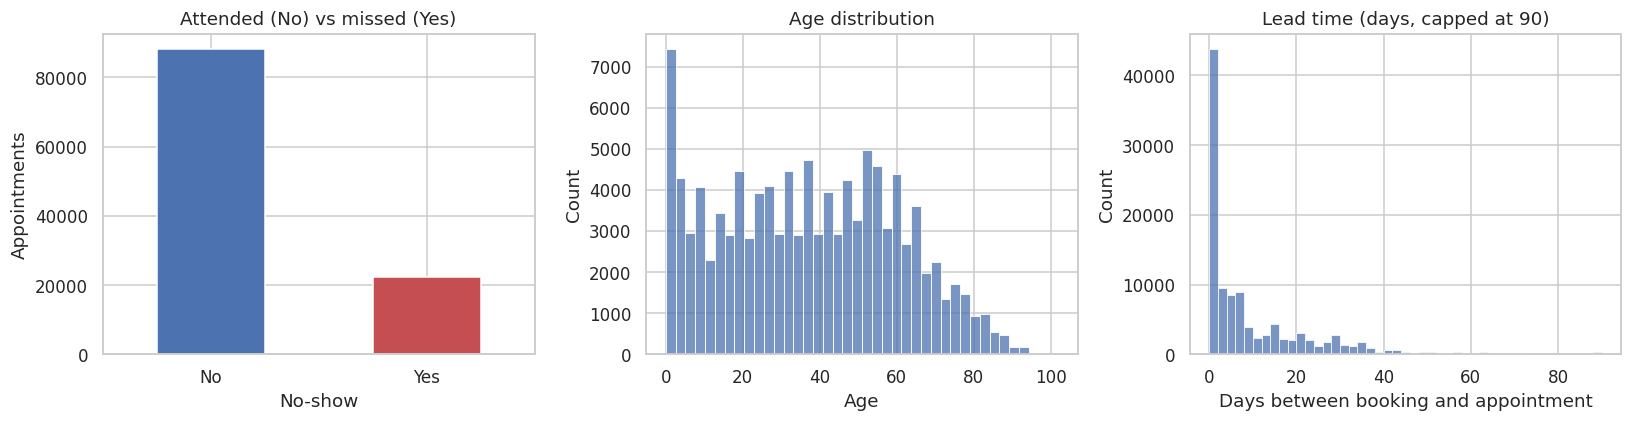

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
df["no_show"].value_counts().plot.bar(ax=ax[0], color=["#4c72b0", "#c44e52"], rot=0)
ax[0].set_title("Attended (No) vs missed (Yes)"); ax[0].set_xlabel("No-show"); ax[0].set_ylabel("Appointments")
sns.histplot(df["age"], bins=40, ax=ax[1], color="#4c72b0")
ax[1].set_title("Age distribution"); ax[1].set_xlabel("Age")
sns.histplot(df["lead_days"].clip(upper=90), bins=45, ax=ax[2], color="#4c72b0")
ax[2].set_title("Lead time (days, capped at 90)"); ax[2].set_xlabel("Days between booking and appointment")
save("01_distributions")

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

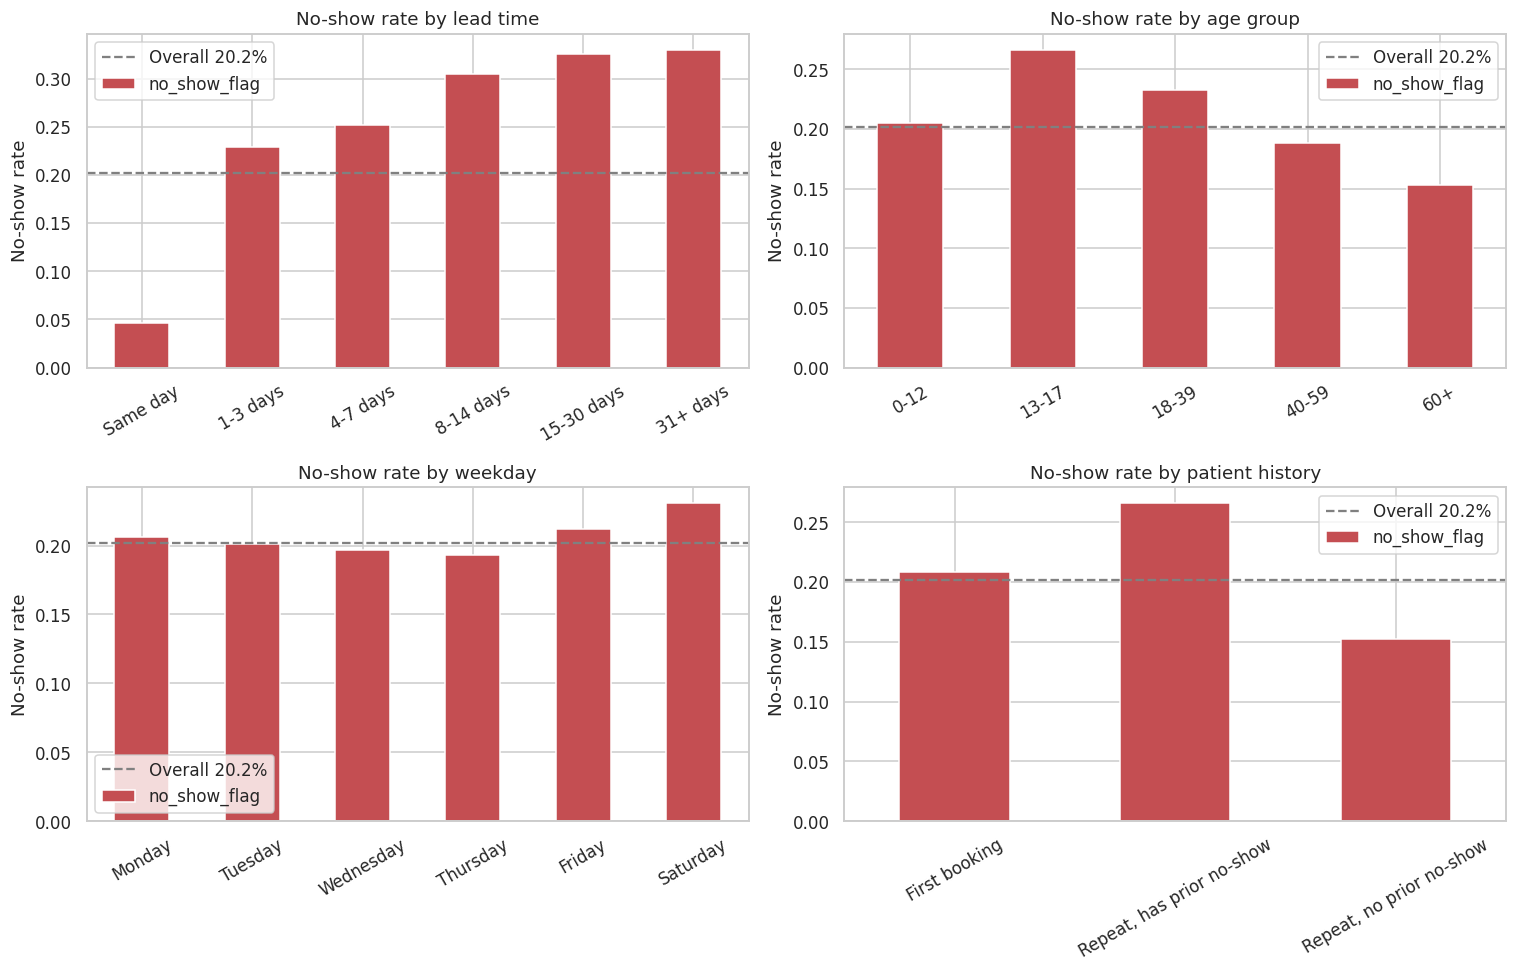

lead_bucket
Same day      0.046
1-3 days      0.229
4-7 days      0.252
8-14 days     0.305
15-30 days    0.326
31+ days      0.330 

age_group
0-12     0.205
13-17    0.266
18-39    0.233
40-59    0.188
60+      0.153 

history
First booking                0.208
Repeat, has prior no-show    0.266
Repeat, no prior no-show     0.152


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [ ]:
def rate_plot(col, ax, title, order=None):
    r = df.groupby(col, observed=True)["no_show_flag"].mean()
    if order is not None:
        r = r.reindex(order)
    r.plot.bar(ax=ax, color="#c44e52", rot=30)
    ax.axhline(overall, ls="--", color="grey", label=f"Overall {overall:.1%}")
    ax.set_title(title); ax.set_ylabel("No-show rate"); ax.set_xlabel(""); ax.legend()
    return r

fig, ax = plt.subplots(2, 2, figsize=(14, 9))
r_lead = rate_plot("lead_bucket", ax[0, 0], "No-show rate by lead time")
r_age = rate_plot("age_group", ax[0, 1], "No-show rate by age group")
r_day = rate_plot("appointment_weekday", ax[1, 0], "No-show rate by weekday",
                  order=["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday"])
df["history"] = np.select([df["prior_visits"] == 0, df["prior_no_shows"] == 0],
                          ["First booking", "Repeat, no prior no-show"], "Repeat, has prior no-show")
r_hist = rate_plot("history", ax[1, 1], "No-show rate by patient history")
save("02_no_show_rates")

print(r_lead.round(3).to_string(), "\n")
print(r_age.round(3).to_string(), "\n")
print(r_hist.round(3).to_string())

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

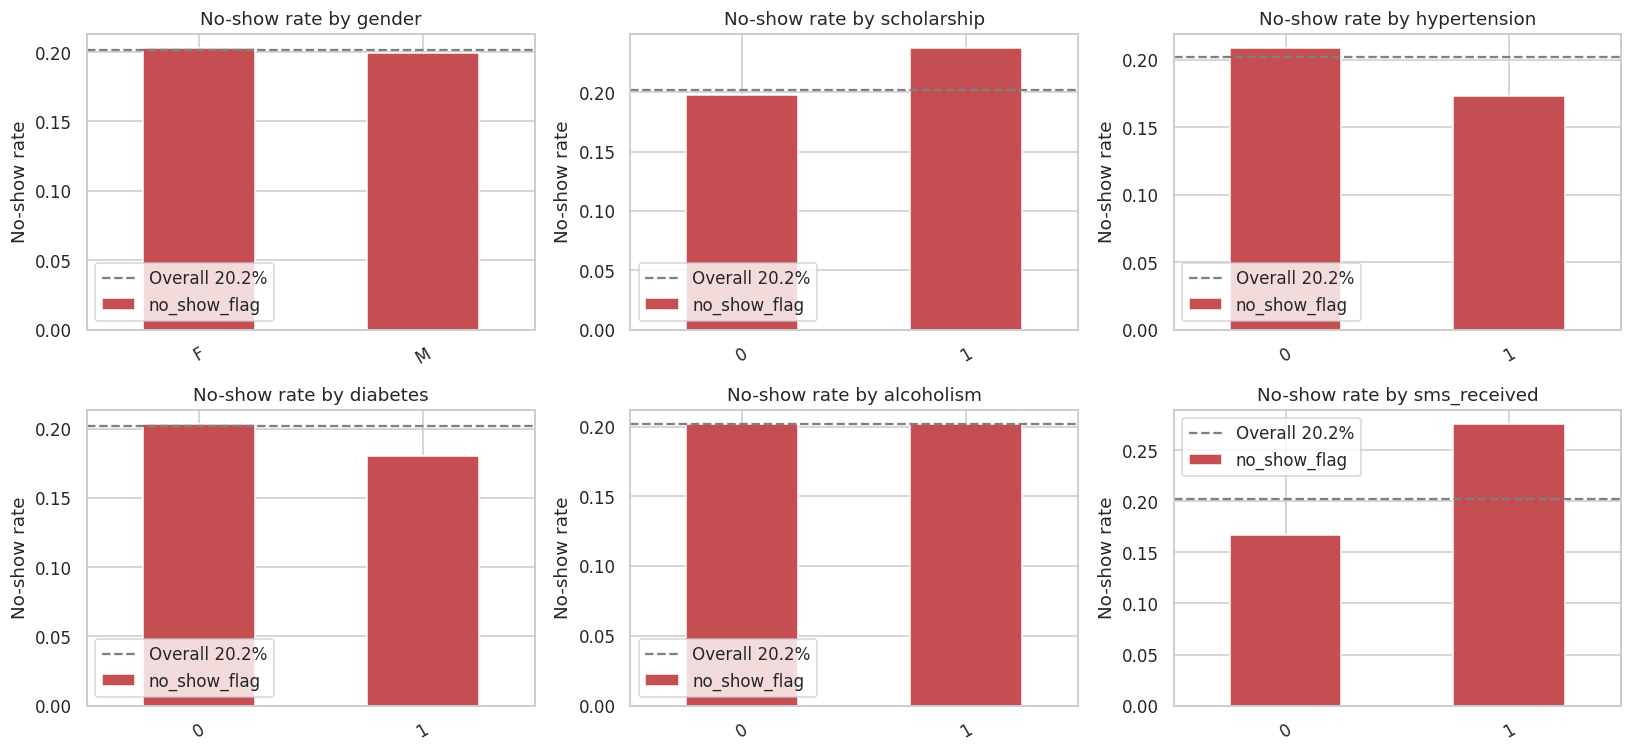

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [ ]:
flags = ["gender", "scholarship", "hypertension", "diabetes", "alcoholism", "sms_received"]
fig, ax = plt.subplots(2, 3, figsize=(15, 7))
for a, col in zip(ax.ravel(), flags):
    rate_plot(col, a, f"No-show rate by {col}")
save("03_no_show_by_flags")

### H1: SMS reminders, controlling for lead time

The raw chart above makes SMS look harmful (reminded patients miss more often). That is misleading: same-day bookings never get an SMS and almost never miss, while SMS goes to patients with long waits. The fair comparison is **within each lead-time bucket**.

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

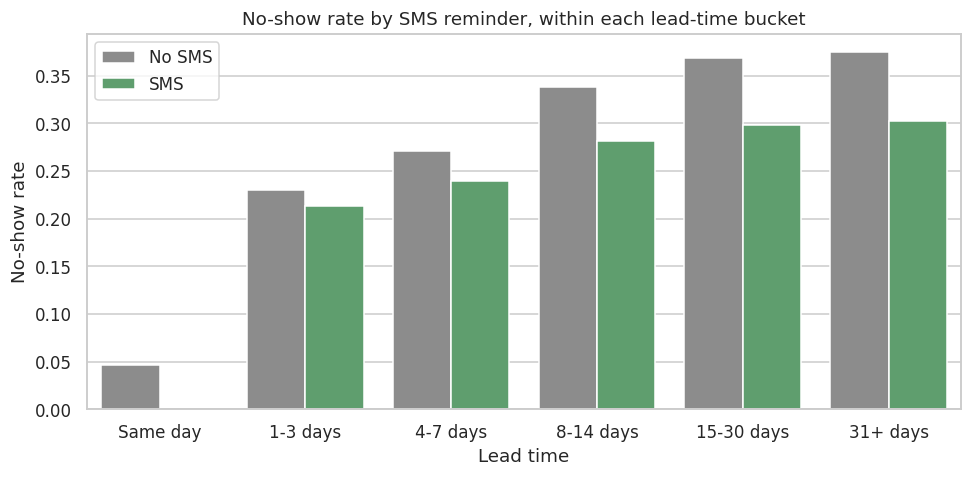

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

no_show_rate        appointments         
sms_received       No SMS    SMS       No SMS      SMS
lead_bucket                                           
Same day            0.046    NaN      38561.0      NaN
1-3 days            0.230  0.213      13767.0    906.0
4-7 days            0.271  0.240       6868.0  10642.0
8-14 days           0.338  0.281       5021.0   7004.0
15-30 days          0.369  0.298       6851.0  10519.0
31+ days            0.375  0.302       3967.0   6410.0

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [ ]:
sms_tbl = (df.groupby(["lead_bucket", "sms_received"], observed=True)["no_show_flag"]
             .agg(no_show_rate="mean", appointments="size").reset_index())
sms_tbl["sms_received"] = sms_tbl["sms_received"].map({0: "No SMS", 1: "SMS"})
sms_tbl.to_csv("results/sms_by_lead_time.csv", index=False)

plt.figure(figsize=(9, 4.5))
sns.barplot(data=sms_tbl, x="lead_bucket", y="no_show_rate", hue="sms_received",
            palette=["#8c8c8c", "#55a868"])
plt.title("No-show rate by SMS reminder, within each lead-time bucket")
plt.xlabel("Lead time"); plt.ylabel("No-show rate"); plt.legend(title="")
save("04_sms_within_lead_time")

sms_tbl.pivot(index="lead_bucket", columns="sms_received", values=["no_show_rate", "appointments"]).round(3)

## 3. Correlation matrix

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

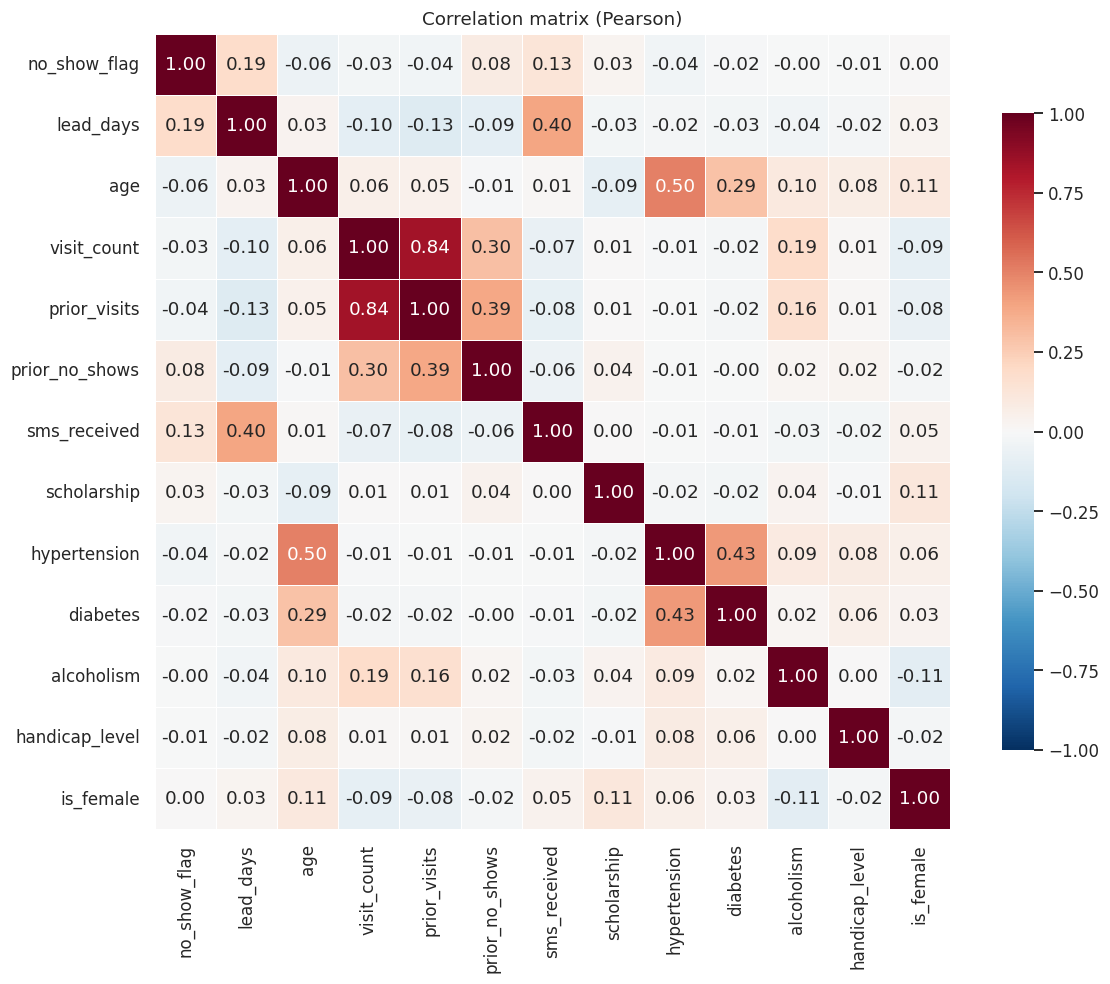

Correlation with no_show_flag:
lead_days         0.186
sms_received      0.127
prior_no_shows    0.084
age              -0.060
hypertension     -0.036
prior_visits     -0.035
visit_count      -0.031
scholarship       0.029
diabetes         -0.015
handicap_level   -0.007
is_female         0.004
alcoholism       -0.000


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [ ]:
corr_cols = ["no_show_flag", "lead_days", "age", "visit_count", "prior_visits", "prior_no_shows",
             "sms_received", "scholarship", "hypertension", "diabetes", "alcoholism", "handicap_level"]
corr_df = df[corr_cols].copy()
corr_df["is_female"] = (df["gender"] == "F").astype(int)
corr = corr_df.corr()
corr.round(4).to_csv("results/correlation_matrix.csv")

plt.figure(figsize=(11, 9))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, center=0,
            square=True, linewidths=.5, cbar_kws={"shrink": .8})
plt.title("Correlation matrix (Pearson)")
save("05_correlation_heatmap")

print("Correlation with no_show_flag:")
print(corr["no_show_flag"].drop("no_show_flag").sort_values(key=abs, ascending=False).round(3).to_string())

## 4. K-Means clustering (H3)

**Unit:** one row per patient (H3 is about patient segments). Each appointment then inherits its patient's cluster.

**Features:** age, average lead time, visit count. Lead time and visit count are heavily right-skewed, so they are log-transformed, then everything is standardised.

`no_show` is **not** used as a clustering feature. It is only used afterwards to check whether the segments differ in no-show rate.

In [ ]:
patients = df.groupby("patient_id").agg(
    age=("age", "max"),
    avg_lead_days=("lead_days", "mean"),
    visit_count=("appointment_id", "size"),
    no_show_rate=("no_show_flag", "mean"),
).reset_index()

X = pd.DataFrame({
    "age": patients["age"],
    "log_lead": np.log1p(patients["avg_lead_days"]),
    "log_visits": np.log1p(patients["visit_count"]),
})
X_scaled = StandardScaler().fit_transform(X)
print("Patients:", len(patients))
patients.describe().round(2)

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Patients: 62296


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,age,avg_lead_days,visit_count,no_show_rate
count,62296.00,62296.00,62296.00,62296.00
mean,36.72,11.16,1.77,0.20
std,23.53,15.06,1.77,0.35
min,0.00,0.00,1.00,0.00
25%,17.00,0.00,1.00,0.00
50%,36.00,5.50,1.00,0.00
75%,56.00,16.50,2.00,0.33
max,102.00,179.00,88.00,1.00


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Streaming output truncated to the last 5000 lines.
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replac

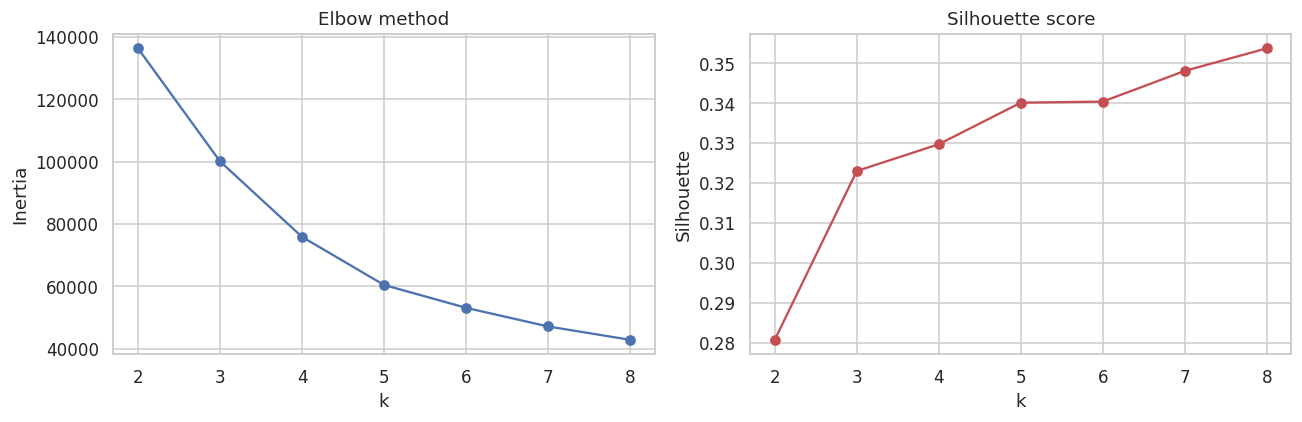

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

,k,inertia,silhouette
0,2,136306.3233,0.2808
1,3,100064.6077,0.3230
2,4,75852.0305,0.3297
3,5,60426.4572,0.3401
4,6,53093.4618,0.3404
5,7,47117.3366,0.3481
6,8,42832.5801,0.3537


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [ ]:
k_results = []
for k in range(2, 9):
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X_scaled)
    sil = silhouette_score(X_scaled, km.labels_, sample_size=10_000, random_state=RANDOM_STATE)
    k_results.append({"k": k, "inertia": km.inertia_, "silhouette": sil})
    experiment_log.append({
        "model": "KMeans", "run": f"k={k}",
        "hyperparameters": f"n_clusters={k}, n_init=10, random_state={RANDOM_STATE}",
        "data": f"{len(patients)} patients; features: age, log1p(avg_lead_days), log1p(visit_count), standardised",
        "metric_1": f"inertia={km.inertia_:.0f}", "metric_2": f"silhouette={sil:.4f}", "notes": ""})
k_results = pd.DataFrame(k_results)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(k_results["k"], k_results["inertia"], "o-"); ax[0].set_title("Elbow method"); ax[0].set_xlabel("k"); ax[0].set_ylabel("Inertia")
ax[1].plot(k_results["k"], k_results["silhouette"], "o-", color="#c44e52"); ax[1].set_title("Silhouette score"); ax[1].set_xlabel("k"); ax[1].set_ylabel("Silhouette")
save("06_kmeans_elbow_silhouette")
k_results.round(4)

In [ ]:
BEST_K = 5   # chosen from the elbow and silhouette results above (see the note below)

final_km = KMeans(n_clusters=BEST_K, n_init=10, random_state=RANDOM_STATE).fit(X_scaled)
patients["cluster"] = final_km.labels_
for row in experiment_log:
    if row["run"] == f"k={BEST_K}":
        row["notes"] = "SELECTED as final model"

profile = patients.groupby("cluster").agg(
    patients=("patient_id", "size"),
    avg_age=("age", "mean"),
    avg_lead_days=("avg_lead_days", "mean"),
    avg_visit_count=("visit_count", "mean"),
).round(2)

# attach clusters to appointments and compute the appointment-level no-show rate
df = df.merge(patients[["patient_id", "cluster"]], on="patient_id", how="left")
profile["appointments"] = df.groupby("cluster").size()
profile["no_show_rate"] = df.groupby("cluster")["no_show_flag"].mean().round(4)
profile.to_csv("results/cluster_profiles.csv")
profile

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

,patients,avg_age,avg_lead_days,avg_visit_count,appointments,no_show_rate
cluster,,,,,,
0,9380,37.39,9.10,4.42,41500,0.2145
1,13519,57.06,23.14,1.31,17665,0.2254
2,12348,58.28,1.18,1.28,15816,0.1096
3,14468,16.46,19.16,1.36,19642,0.3250
4,12581,16.49,0.39,1.26,15893,0.0826


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

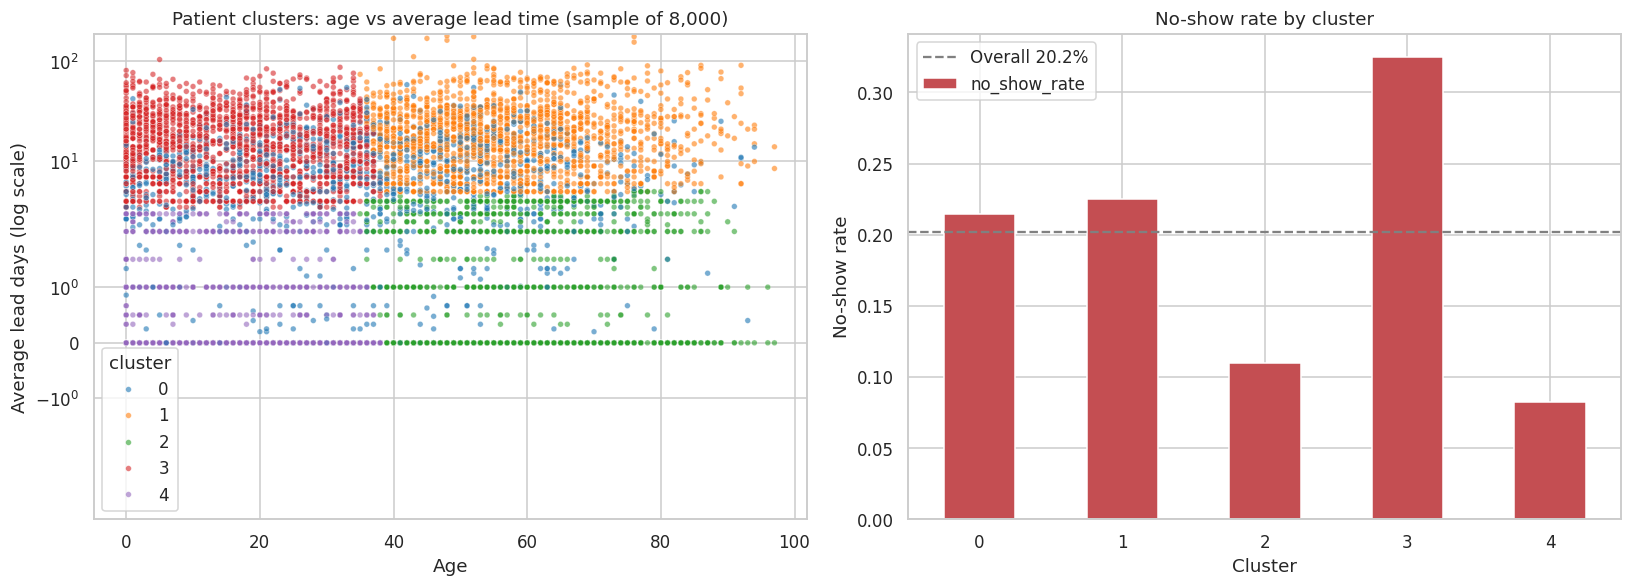

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

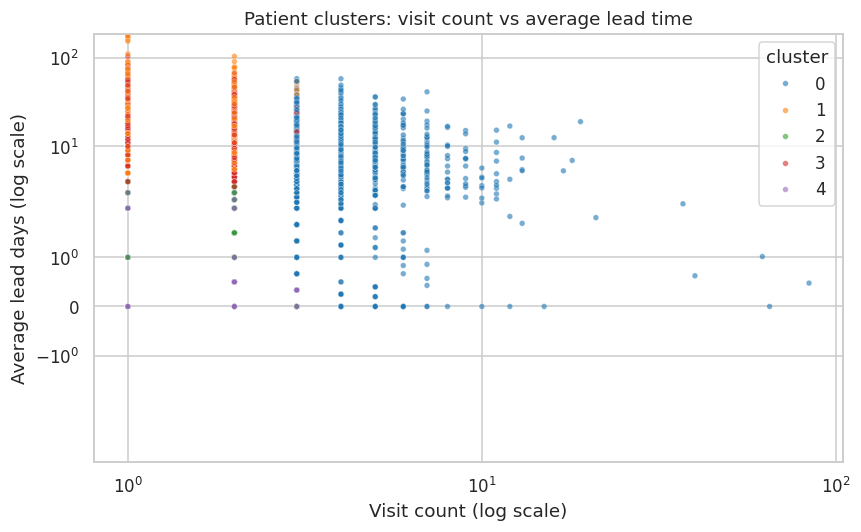

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(15, 5.5))
samp = patients.sample(8000, random_state=RANDOM_STATE)
sns.scatterplot(data=samp, x="age", y="avg_lead_days", hue="cluster", palette="tab10",
                s=14, alpha=.6, ax=ax[0])
ax[0].set_yscale("symlog"); ax[0].set_title("Patient clusters: age vs average lead time (sample of 8,000)")
ax[0].set_xlabel("Age"); ax[0].set_ylabel("Average lead days (log scale)")

profile["no_show_rate"].plot.bar(ax=ax[1], color="#c44e52", rot=0)
ax[1].axhline(overall, ls="--", color="grey", label=f"Overall {overall:.1%}")
ax[1].set_title("No-show rate by cluster"); ax[1].set_xlabel("Cluster"); ax[1].set_ylabel("No-show rate"); ax[1].legend()
save("07_kmeans_clusters")

plt.figure(figsize=(8, 5))
sns.scatterplot(data=samp, x="visit_count", y="avg_lead_days", hue="cluster", palette="tab10", s=14, alpha=.6)
plt.xscale("log"); plt.yscale("symlog")
plt.title("Patient clusters: visit count vs average lead time"); plt.xlabel("Visit count (log scale)"); plt.ylabel("Average lead days (log scale)")
save("08_kmeans_clusters_visits")

### Choosing k and reading the clusters

**k = 5 was selected.** The elbow plot shows inertia falling steeply up to k = 5 (a drop of about 15,400 from k = 4 to 5) and then flattening (about 7,300 from 5 to 6). The silhouette score keeps creeping up after that, but only from 0.340 at k = 5 to 0.354 at k = 8, which is too small a gain to justify harder-to-explain segments. Silhouette values around 0.34 mean the segments overlap moderately; they are useful groupings, not sharply separated ones.

| Cluster | Segment | Avg age | Avg lead days | Avg visits | No-show rate |
|---|---|---|---|---|---|
| 0 | Frequent visitors | 37 | 9.1 | 4.4 | 21.4% |
| 1 | Older, book far ahead | 57 | 23.1 | 1.3 | 22.5% |
| 2 | Older, short notice | 58 | 1.2 | 1.3 | 11.0% |
| 3 | Young, book far ahead | 16 | 19.2 | 1.4 | 32.5% |
| 4 | Young, short notice | 16 | 0.4 | 1.3 | 8.3% |

**H3 is supported.** No-show rates range from 8.3% to 32.5% across segments, against 20.2% overall. Lead time separates the segments most: both short-notice clusters sit near 10%, both book-ahead clusters are above average, and among patients who book ahead the young miss far more often than the old (32.5% vs 22.5%).

**Reminder strategy by segment:** cluster 3 (young, long wait) is the priority for reminders or overbooking; clusters 2 and 4 need little intervention; cluster 0 is large in appointment volume (41,500 appointments) so even an average rate produces the most missed slots in absolute terms.

## 5. Association rules (Apriori, mlxtend)

Each appointment becomes a basket of yes/no items (age group, lead-time bucket, SMS, health flags, history, outcome). We look for item combinations that lead to **`no_show=Yes`**.

Because no-shows are only about 20% of appointments, a rule's confidence should be judged against that base rate. **Lift** does this directly: lift 1.5 means a no-show is 1.5 times more likely than average when the rule's conditions hold.

In [ ]:
basket = pd.DataFrame({
    "gender=F": df["gender"] == "F",
    "gender=M": df["gender"] == "M",
    "sms=Yes": df["sms_received"] == 1,
    "sms=No": df["sms_received"] == 0,
    "scholarship": df["scholarship"] == 1,
    "hypertension": df["hypertension"] == 1,
    "diabetes": df["diabetes"] == 1,
    "alcoholism": df["alcoholism"] == 1,
    "handicap": df["handicap_level"] > 0,
    "first_booking": df["prior_visits"] == 0,
    "prior_no_show": df["prior_no_shows"] > 0,
    "no_show=Yes": df["no_show_flag"] == 1,
    "no_show=No": df["no_show_flag"] == 0,
})
basket = pd.concat([basket,
                    pd.get_dummies(df["age_group"], prefix="age", prefix_sep="=").astype(bool),
                    pd.get_dummies(df["lead_bucket"], prefix="lead", prefix_sep="=").astype(bool)], axis=1)
print("Basket shape:", basket.shape)
basket.mean().sort_values(ascending=False).round(3).to_frame("share of appointments").T

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Basket shape: (110516, 24)


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,no_show=No,sms=No,gender=F,first_booking,gender=M,lead=Same day,sms=Yes,age=18-39,age=40-59,no_show=Yes,...,prior_no_show,lead=15-30 days,lead=1-3 days,lead=8-14 days,scholarship,lead=31+ days,diabetes,age=13-17,alcoholism,handicap
share of appointments,0.798,0.679,0.65,0.564,0.35,0.349,0.321,0.289,0.272,0.202,...,0.158,0.157,0.133,0.109,0.098,0.094,0.072,0.057,0.03,0.02


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [ ]:
TARGET = frozenset({"no_show=Yes"})
rule_sets = {}
for min_sup in [0.05, 0.02, 0.01, 0.005]:
    itemsets = apriori(basket, min_support=min_sup, use_colnames=True, max_len=4)
    for min_conf in [0.25, 0.30, 0.35]:
        rules = association_rules(itemsets, metric="confidence", min_threshold=min_conf)
        target_rules = rules[rules["consequents"] == TARGET]
        rule_sets[(min_sup, min_conf)] = target_rules
        experiment_log.append({
            "model": "Apriori", "run": f"sup={min_sup}, conf={min_conf}",
            "hyperparameters": f"min_support={min_sup}, min_confidence={min_conf}, max_len=4",
            "data": f"{len(basket)} appointments, {basket.shape[1]} items",
            "metric_1": f"itemsets={len(itemsets)}, no_show_rules={len(target_rules)}",
            "metric_2": (f"max_lift={target_rules['lift'].max():.3f}, max_conf={target_rules['confidence'].max():.3f}"
                         if len(target_rules) else "no rules"),
            "notes": ""})

pd.DataFrame([r for r in experiment_log if r["model"] == "Apriori"])[["run", "metric_1", "metric_2"]]

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

,run,metric_1,metric_2
0,"sup=0.05, conf=0.25","itemsets=285, no_show_rules=4","max_lift=1.614, max_conf=0.326"
1,"sup=0.05, conf=0.3","itemsets=285, no_show_rules=1","max_lift=1.614, max_conf=0.326"
2,"sup=0.05, conf=0.35","itemsets=285, no_show_rules=0",no rules
3,"sup=0.02, conf=0.25","itemsets=724, no_show_rules=22","max_lift=1.826, max_conf=0.369"
4,"sup=0.02, conf=0.3","itemsets=724, no_show_rules=12","max_lift=1.826, max_conf=0.369"
5,"sup=0.02, conf=0.35","itemsets=724, no_show_rules=1","max_lift=1.826, max_conf=0.369"
6,"sup=0.01, conf=0.25","itemsets=1306, no_show_rules=67","max_lift=1.880, max_conf=0.380"
7,"sup=0.01, conf=0.3","itemsets=1306, no_show_rules=35","max_lift=1.880, max_conf=0.380"
8,"sup=0.01, conf=0.35","itemsets=1306, no_show_rules=10","max_lift=1.880, max_conf=0.380"
9,"sup=0.005, conf=0.25","itemsets=2020, no_show_rules=143","max_lift=2.450, max_conf=0.495"


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [ ]:
FINAL_SUP, FINAL_CONF = 0.01, 0.30
for row in experiment_log:
    if row["run"] == f"sup={FINAL_SUP}, conf={FINAL_CONF}":
        row["notes"] = "SELECTED as final rule set"

final_rules = rule_sets[(FINAL_SUP, FINAL_CONF)].copy()
final_rules["antecedents"] = final_rules["antecedents"].apply(lambda s: ", ".join(sorted(s)))
final_rules["consequents"] = final_rules["consequents"].apply(lambda s: ", ".join(sorted(s)))
final_rules["n_conditions"] = final_rules["antecedents"].str.count(",") + 1
final_rules["appointments_matching"] = (final_rules["antecedent support"] * len(basket)).round().astype(int)
final_rules = (final_rules[["antecedents", "consequents", "n_conditions", "antecedent support", "support",
                            "confidence", "lift", "leverage", "conviction", "appointments_matching"]]
               .sort_values(["lift", "support"], ascending=False).reset_index(drop=True))
final_rules.to_csv("results/association_rules.csv", index=False)

print(f"{len(final_rules)} rules lead to a no-show (min_support={FINAL_SUP}, min_confidence={FINAL_CONF})")
final_rules.head(15).round(4)

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

35 rules lead to a no-show (min_support=0.01, min_confidence=0.3)


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,antecedents,consequents,n_conditions,antecedent support,support,confidence,lift,leverage,conviction,appointments_matching
0,"age=18-39, lead=15-30 days",no_show=Yes,2,0.0489,0.0185,0.3795,1.8799,0.0087,1.2863,5399
1,"age=18-39, first_booking, lead=15-30 days",no_show=Yes,3,0.0319,0.0120,0.3751,1.8582,0.0055,1.2773,3524
2,"lead=31+ days, sms=No",no_show=Yes,2,0.0359,0.0135,0.3751,1.8580,0.0062,1.2772,3967
3,"first_booking, lead=31+ days, sms=No",no_show=Yes,3,0.0290,0.0108,0.3738,1.8513,0.0050,1.2744,3200
4,"lead=15-30 days, sms=No",no_show=Yes,2,0.0620,0.0229,0.3687,1.8264,0.0103,1.2643,6851
5,"age=18-39, gender=F, lead=15-30 days",no_show=Yes,3,0.0371,0.0136,0.3670,1.8181,0.0061,1.2609,4103
6,"age=18-39, lead=15-30 days, sms=Yes",no_show=Yes,3,0.0309,0.0111,0.3601,1.7836,0.0049,1.2472,3416
7,"gender=F, lead=15-30 days, sms=No",no_show=Yes,3,0.0403,0.0145,0.3600,1.7831,0.0064,1.2470,4453
8,"first_booking, lead=15-30 days, sms=No",no_show=Yes,3,0.0427,0.0153,0.3578,1.7725,0.0067,1.2429,4720
9,"gender=F, prior_no_show, sms=Yes",no_show=Yes,3,0.0294,0.0104,0.3529,1.7483,0.0044,1.2335,3247


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

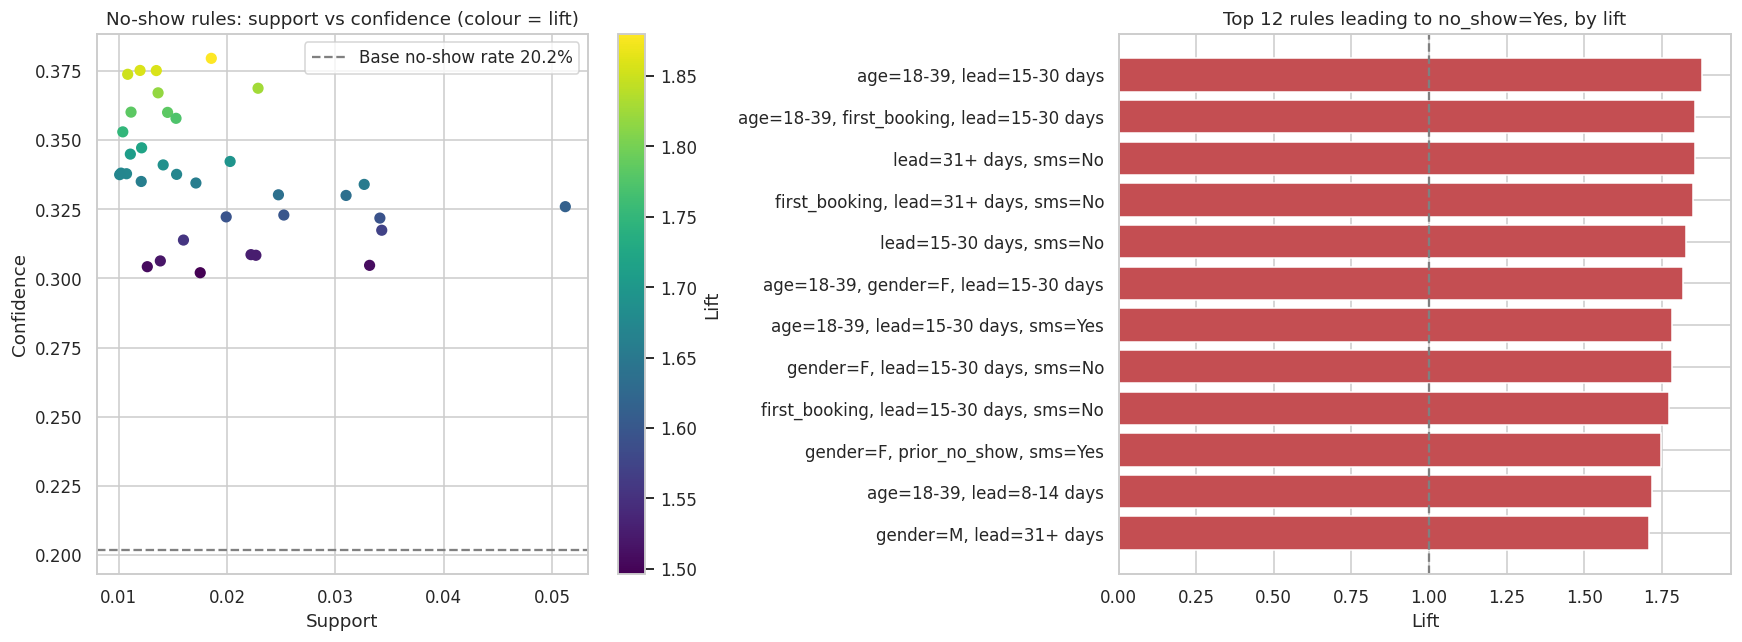

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(16, 6))
sc = ax[0].scatter(final_rules["support"], final_rules["confidence"], c=final_rules["lift"], cmap="viridis", s=40)
ax[0].axhline(overall, ls="--", color="grey", label=f"Base no-show rate {overall:.1%}")
ax[0].set_title("No-show rules: support vs confidence (colour = lift)")
ax[0].set_xlabel("Support"); ax[0].set_ylabel("Confidence"); ax[0].legend()
plt.colorbar(sc, ax=ax[0], label="Lift")

top = final_rules.head(12).iloc[::-1]
ax[1].barh(top["antecedents"], top["lift"], color="#c44e52")
ax[1].axvline(1, ls="--", color="grey")
ax[1].set_title("Top 12 rules leading to no_show=Yes, by lift"); ax[1].set_xlabel("Lift")
save("09_association_rules")

### Reading the rules

**Final setting: min_support = 0.01, min_confidence = 0.30, which gives 35 rules.** At support 0.05 only 1 rule survives; at 0.005 the list grows to 77 rules and each covers as few as 550 appointments. Confidence 0.30 means the rule's group misses at least 1.5 times as often as the 20.2% base rate.

- **Long lead time appears in most of the strongest rules.** `lead=15-30 days` alone gives 32.6% no-shows (lift 1.61); `lead=31+ days` gives 33.0% (lift 1.63).
- **The strongest rule is `age=18-39` + `lead=15-30 days`**: 38.0% no-shows, lift 1.88, covering 5,399 appointments.
- **Long wait without a reminder is worse**: `lead=31+ days` + `sms=No` gives 37.5% (lift 1.86), compared with 33.0% for `lead=31+ days` overall.
- **A previous no-show matters**: `prior_no_show` + `sms=Yes` gives 34.1% (lift 1.69).

**Caution on `sms=Yes` rules.** Several rules contain `sms=Yes`, but this does not mean reminders cause no-shows. SMS is only sent for appointments booked ahead, so `sms=Yes` is acting as a stand-in for "long lead time". Section 2 shows that within every lead-time bucket, reminded patients miss less often.

## 6. Experiment log and exports

In [ ]:
log = pd.DataFrame(experiment_log)
log.insert(0, "experiment_id", range(1, len(log) + 1))
log.to_csv("results/experiment_log.csv", index=False)

out_cols = ["appointment_id", "patient_id", "gender", "age", "age_group", "scheduled_at", "appointment_date",
            "appointment_weekday", "lead_days", "lead_bucket", "visit_count", "prior_visits", "prior_no_shows",
            "sms_received", "scholarship", "hypertension", "diabetes", "alcoholism", "handicap_level",
            "neighbourhood", "no_show", "no_show_flag", "cluster"]
df.sort_values("appointment_id")[out_cols].to_csv("results/cluster_assignments.csv", index=False)

print("results/:", sorted(os.listdir("results")))
print("figures/:", sorted(os.listdir("figures")))
log

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

results/: ['association_rules.csv', 'cluster_assignments.csv', 'cluster_profiles.csv', 'correlation_matrix.csv', 'experiment_log.csv', 'sms_by_lead_time.csv']
figures/: ['01_distributions.png', '02_no_show_rates.png', '03_no_show_by_flags.png', '04_sms_within_lead_time.png', '05_correlation_heatmap.png', '06_kmeans_elbow_silhouette.png', '07_kmeans_clusters.png', '08_kmeans_clusters_visits.png', '09_association_rules.png']


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,experiment_id,model,run,hyperparameters,data,metric_1,metric_2,notes
0,1,KMeans,k=2,"n_clusters=2, n_init=10, random_state=42","62296 patients; features: age, log1p(avg_lead_...",inertia=136306,silhouette=0.2808,
1,2,KMeans,k=3,"n_clusters=3, n_init=10, random_state=42","62296 patients; features: age, log1p(avg_lead_...",inertia=100065,silhouette=0.3230,
2,3,KMeans,k=4,"n_clusters=4, n_init=10, random_state=42","62296 patients; features: age, log1p(avg_lead_...",inertia=75852,silhouette=0.3297,
3,4,KMeans,k=5,"n_clusters=5, n_init=10, random_state=42","62296 patients; features: age, log1p(avg_lead_...",inertia=60426,silhouette=0.3401,SELECTED as final model
4,5,KMeans,k=6,"n_clusters=6, n_init=10, random_state=42","62296 patients; features: age, log1p(avg_lead_...",inertia=53093,silhouette=0.3404,
5,6,KMeans,k=7,"n_clusters=7, n_init=10, random_state=42","62296 patients; features: age, log1p(avg_lead_...",inertia=47117,silhouette=0.3481,
6,7,KMeans,k=8,"n_clusters=8, n_init=10, random_state=42","62296 patients; features: age, log1p(avg_lead_...",inertia=42833,silhouette=0.3537,
7,8,Apriori,"sup=0.05, conf=0.25","min_support=0.05, min_confidence=0.25, max_len=4","110516 appointments, 24 items","itemsets=285, no_show_rules=4","max_lift=1.614, max_conf=0.326",
8,9,Apriori,"sup=0.05, conf=0.3","min_support=0.05, min_confidence=0.3, max_len=4","110516 appointments, 24 items","itemsets=285, no_show_rules=1","max_lift=1.614, max_conf=0.326",
9,10,Apriori,"sup=0.05, conf=0.35","min_support=0.05, min_confidence=0.35, max_len=4","110516 appointments, 24 items","itemsets=285, no_show_rules=0",no rules,


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

## Summary of findings

| Phase 1 item | Finding |
|---|---|
| Sub-question 1 (which booking-time factors matter) | Lead time is the strongest single factor: 4.6% no-shows for same-day bookings, rising to 33.0% for 31+ days (correlation 0.19). Age (teens and 18-39 miss most, 60+ least) and a prior no-show (26.6% vs 15.2% for repeat patients without one) also separate the groups. Health flags and gender show almost no relationship. |
| H1 (SMS reduces no-shows after accounting for lead time) | Supported descriptively. In every lead-time bucket where SMS is sent, reminded patients miss less: by 1.7 points at 1-3 days and by 3 to 7 points in the longer buckets. This is a comparison of rates, not a significance test or a causal estimate. |
| H3 (distinct segments with different no-show rates) | Supported. Five patient segments with no-show rates from 8.3% to 32.5%. |
| H2 and sub-question 4 | Belong to the predictive models; not tested here. |

**Limitations**

- Correlations are weak overall (largest is 0.19), so no single variable predicts a no-show well.
- The clusters overlap (silhouette about 0.34).
- `visit_count` and the patient's average lead time use all of a patient's appointments in the dataset, so the clusters describe patients in hindsight. For the predictive model, use `prior_visits` and `prior_no_shows`, which only use information known at booking time.
- The 618 near-duplicate rows were kept, as in Phase 1.